In [1]:
#Importación de librerías y carga de datos

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Cargamos el archivo de usuarios
df_usuarios = pd.read_csv('usuarios_win_mac_lin.csv')

print("Dimensiones:", df_usuarios.shape)
display(df_usuarios.head())
print("\nDistribución por sistema operativo:")
print(df_usuarios['clase'].value_counts().rename(index={0: '0 - Windows', 1: '1 - Macintosh', 2: '2 - Linux'}))

Dimensiones: (170, 5)


,duracion,paginas,acciones,valor,clase
0,7.0,2,4,8,2
1,21.0,2,6,6,2
2,57.0,2,4,4,2
3,101.0,3,6,12,2
4,109.0,2,6,12,2



Distribución por sistema operativo:
clase
0 - Windows      86
2 - Linux        44
1 - Macintosh    40
Name: count, dtype: int64


,duracion,paginas,acciones,valor,clase
count,170.000000,170.000000,170.000000,170.000000,170.000000
mean,111.075729,2.041176,8.723529,32.676471,0.752941
std,202.453200,1.500911,9.136054,44.751993,0.841327
min,1.000000,1.000000,1.000000,1.000000,0.000000
25%,11.000000,1.000000,3.000000,8.000000,0.000000
50%,13.000000,2.000000,6.000000,20.000000,0.000000
75%,108.000000,2.000000,10.000000,36.000000,2.000000
max,898.000000,9.000000,63.000000,378.000000,2.000000


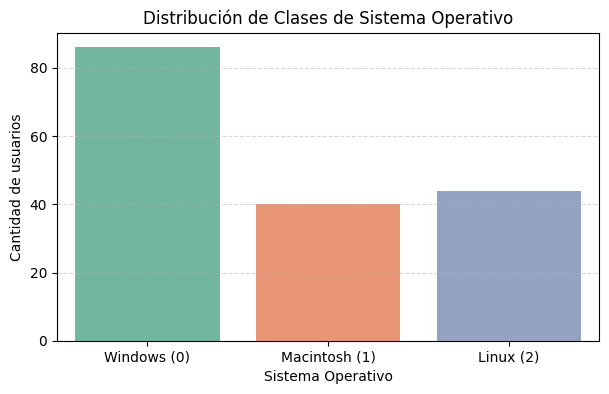

In [3]:
# Estadísticas descriptivas
display(df_usuarios.describe())

# Visualización de la distribución de clases
plt.figure(figsize=(7, 4))
sns.countplot(data=df_usuarios, x='clase', hue='clase', palette='Set2', legend=False)
plt.title("Distribución de Clases de Sistema Operativo")
plt.xticks(ticks=[0, 1, 2], labels=['Windows (0)', 'Macintosh (1)', 'Linux (2)'])
plt.xlabel("Sistema Operativo")
plt.ylabel("Cantidad de usuarios")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

In [ ]:
# Variables predictoras (X) y variable objetivo (y)
X = df_usuarios[['duracion', 'paginas', 'acciones', 'valor']]
y = df_usuarios['clase']

# Partición: 80% entrenamiento y 20% prueba 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Muestras de entrenamiento: {X_train.shape[0]}")
print(f"Muestras de prueba: {X_test.shape[0]}")

Muestras de entrenamiento: 136
Muestras de prueba: 34


Exactitud (Accuracy) en prueba: 0.74 (73.5%)

Reporte de Clasificación:
              precision    recall  f1-score   support

     Windows       0.75      0.71      0.73        17
   Macintosh       1.00      0.50      0.67         8
       Linux       0.64      1.00      0.78         9

    accuracy                           0.74        34
   macro avg       0.80      0.74      0.73        34
weighted avg       0.78      0.74      0.73        34



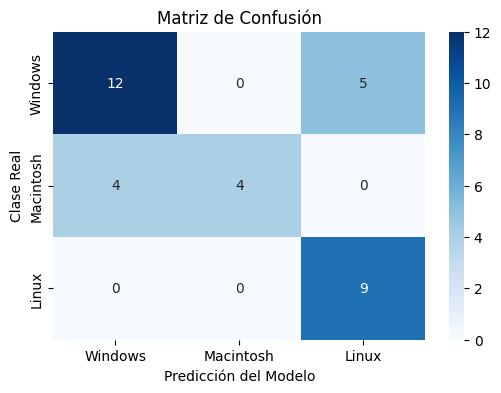

In [5]:
# Crear y ajustar el clasificador de Regresión Logística
clasificador = LogisticRegression(solver='lbfgs', max_iter=1000, random_state=42)
clasificador.fit(X_train, y_train)

# Predicciones sobre el conjunto de prueba
y_pred = clasificador.predict(X_test)

# Métricas de evaluación
acc = accuracy_score(y_test, y_pred)
print(f"Exactitud (Accuracy) en prueba: {acc:.2f} ({acc*100:.1f}%)\n")

print("Reporte de Clasificación:")
print(classification_report(y_test, y_pred, target_names=['Windows', 'Macintosh', 'Linux']))

# Matriz de Confusión
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Windows', 'Macintosh', 'Linux'],
            yticklabels=['Windows', 'Macintosh', 'Linux'])
plt.title("Matriz de Confusión")
plt.xlabel("Predicción del Modelo")
plt.ylabel("Clase Real")
plt.show()

In [6]:
# Ejemplo de nuevos usuarios:
# Usuario 1: navega 120s, 6 páginas, 12 acciones, valor 15
# Usuario 2: navega 15s, 1 página, 2 acciones, valor 2
nuevos_usuarios = pd.DataFrame([
    {'duracion': 120, 'paginas': 6, 'acciones': 12, 'valor': 15},
    {'duracion': 15, 'paginas': 1, 'acciones': 2, 'valor': 2}
])

predicciones = clasificador.predict(nuevos_usuarios)
mapa_so = {0: 'Windows', 1: 'Macintosh', 2: 'Linux'}

for i, p in enumerate(predicciones):
    print(f"Usuario {i+1}: Clasificado como -> {mapa_so[p]}")

Usuario 1: Clasificado como -> Linux
Usuario 2: Clasificado como -> Linux
